# Dataset analítico y análisis exploratorio (OE2)

Ensambla la tabla que alimenta el análisis espacial y el modelamiento, y describe la distribución de las tres medidas de resultado según las características del establecimiento.

**Requiere** haber ejecutado los notebooks 01, 02 y 03.

### Qué entra en el dataset

| Bloque | Variables |
|---|---|
| Resultados | `caida_inicial`, `recuperacion`, `recuperacion_relativa`, `tipo_trayectoria` |
| Composición | grupo socioeconómico, dependencia, ruralidad, matrícula PRE/POST |
| Territorio | región y comuna **del Directorio** (las del archivo SIMCE no son fiables en 2015) |
| Geografía derivada | densidad de la red escolar, aislamiento, posición en la comuna, centralidad nacional |

Las coordenadas crudas **no** se usan como predictores: un modelo de árboles las particionaría hasta memorizar la ubicación de cada colegio, y entonces su contribución SHAP no sería interpretable como efecto del entorno. En su lugar se construyen variables geográficas que significan algo por sí solas.

> **Revisión del 24-oct-2026 (auditoría de cuadernos y código).** Sin cambios de código. Se vuelve a ejecutar porque el cuaderno 02 redefinió `recuperacion_relativa` (solo para los que cayeron al menos 1 punto).

**Salida esperada:** en la descripción de la muestra (2.821 establecimientos), `recuperacion_relativa` pasa a count 1.856, mediana 0,60, p25 0,08 y p75 1,42 (antes 2.721; 0,54; −0,08; 1,44). El resto de las salidas no cambia.

In [1]:
import sys
from pathlib import Path

for m in list(sys.modules):
    if m == "simce_panel" or m.startswith("simce_panel."):
        del sys.modules[m]
candidatos = [Path.cwd() / "simce_panel" / "src", Path.cwd().parent / "src", Path.cwd() / "src"]
RUTA_SRC = next((p for p in candidatos if (p / "simce_panel" / "__init__.py").exists()), None)
if RUTA_SRC is None:
    raise FileNotFoundError("No encontré 'src/simce_panel'.")
sys.path.insert(0, str(RUTA_SRC))

import numpy as np
import pandas as pd
import simce_panel as sp
sp.configurar_logging()
D = sp.dataset
print("simce_panel", sp.__version__)

simce_panel 1.1.0


In [2]:
BASE_DIR = "."
cfg = sp.Config.desde_base(BASE_DIR)

MATERIA = "mate"        # cambia a "lect" para replicar el análisis en Lectura

resultados = sp.io_datos.leer_csv(cfg.ruta_salida(f"resultados_{MATERIA}_2m.csv"))
ancho = sp.io_datos.leer_csv(cfg.ruta_salida("simce_rbd_ancho_reducido_2015_2025.csv"))
print("resultados:", resultados.shape, "| panel ancho:", ancho.shape)

resultados: (3144, 20) | panel ancho: (3160, 45)


## 1. Ensamblaje

Las variables geográficas se calculan con la métrica **haversine**, no con distancia euclidiana sobre grados. En Chile un grado de longitud mide unos 104 km en Arica y 62 km en Punta Arenas: tratar los grados como un plano distorsionaría las distancias justo según la latitud, que es la dimensión que interesa analizar.

In [3]:
datos = D.ensamblar_dataset(resultados, ancho, materia=MATERIA)
print("Dataset analítico:", datos.shape)
print("\nVariables geográficas derivadas:")
geo_cols = [c for c in datos.columns if c.startswith(("densidad", "dist_"))]
datos[geo_cols].describe().round(1)

15:14:48 | INFO    | simce_panel.dataset | Variables geográficas calculadas para 3158 establecimientos.


15:14:48 | INFO    | simce_panel.dataset | Dataset analítico: 3144 filas x 39 columnas.


Dataset analítico: (3144, 39)

Variables geográficas derivadas:


,densidad_5km,densidad_10km,dist_vecino_km,dist_k_vecinos_km,dist_centroide_comuna_km,dist_referencia_km
count,3144.0,3144.0,3144.0,3144.0,3144.0,3144.0
mean,45.3,121.0,2.0,5.8,3.7,339.4
std,46.0,148.5,13.7,64.2,8.1,446.1
min,0.0,0.0,0.0,0.2,0.0,0.7
25%,8.0,14.0,0.2,0.5,0.9,16.9
50%,30.0,49.0,0.4,0.8,1.7,101.2
75%,62.0,182.2,0.7,1.7,2.9,474.7
max,186.0,518.0,607.0,2015.6,65.7,3766.0


**Verificación de las distancias.** Antes de usarlas conviene comprobar que los valores extremos corresponden a lugares reales y no a errores de cálculo.

In [4]:
extremos = datos.nlargest(3, "dist_referencia_km")[
    ["rbd", "nom_rbd", "region_dir", "dist_referencia_km", "dist_vecino_km"]]
extremos.round(1)

[Salida omitida en la versión pública: mostraba nombres de establecimientos.]


## 2. La muestra analítica y el sesgo de selección

No todos los establecimientos tienen las dos medidas de resultado: algunos carecen de años suficientes en PRE o en POST, sea por supresión de puntajes o por no existir en esos años.

Los excluidos **no son una muestra aleatoria**. Cuantificar en qué se diferencian es un requisito para interpretar cualquier resultado posterior, y es el contenido del Anexo de sesgo de selección de la tesis.

In [5]:
datos["en_muestra"] = datos["muestra_analitica"].fillna(False).astype(bool)
print(datos["en_muestra"].value_counts().rename({True: "en la muestra",
                                                  False: "excluido"}).to_string())

filas = []
for var in ["cod_grupo_cat", "cod_depe1_cat", "cod_rural_rbd_cat"]:
    if var not in datos.columns:
        continue
    t = pd.crosstab(datos[var], datos["en_muestra"], normalize="columns") * 100
    t.columns = ["excluidos_%", "en_muestra_%"]
    t["diferencia_pp"] = (t["en_muestra_%"] - t["excluidos_%"]).round(1)
    t["variable"] = var
    filas.append(t.round(1))
sesgo = pd.concat(filas)
sesgo

en_muestra
en la muestra    2821
excluido          323


,excluidos_%,en_muestra_%,diferencia_pp,variable
Alto,15.8,15.2,-0.6,cod_grupo_cat
Bajo,19.2,20.3,1.1,cod_grupo_cat
Medio,26.3,23.8,-2.5,cod_grupo_cat
Medio alto,7.1,12.5,5.4,cod_grupo_cat
Medio bajo,31.6,28.2,-3.4,cod_grupo_cat
Corporación de administración delegada,0.0,2.5,2.5,cod_depe1_cat
Municipal Corporación,4.6,4.1,-0.5,cod_depe1_cat
Municipal DAEM,12.4,13.9,1.5,cod_depe1_cat
Particular pagado,19.2,14.8,-4.4,cod_depe1_cat
Particular subvencionado,56.7,53.9,-2.8,cod_depe1_cat


**Cómo leerlo.** Cada columna suma 100 % dentro de su grupo. Una diferencia positiva indica que esa categoría está **sobrerrepresentada** en la muestra analítica; negativa, que está subrepresentada. Diferencias grandes obligan a acotar el alcance de las conclusiones sobre ese segmento.

In [6]:
# Tamaño de los establecimientos incluidos frente a los excluidos.
comp = datos.groupby("en_muestra")[["matricula_pre", "matricula_post",
                                     "densidad_5km", "dist_referencia_km"]].median()
comp.round(1)

,matricula_pre,matricula_post,densidad_5km,dist_referencia_km
en_muestra,,,,
False,24.0,26.6,25.0,91.4
True,52.0,57.0,30.0,102.5


## 3. Distribución de las medidas por características del establecimiento

A partir de aquí se trabaja sobre la muestra analítica.

In [7]:
m = datos[datos.en_muestra].copy()
print("Establecimientos en el análisis:", len(m))

MEDIDAS = ("caida_inicial", "recuperacion", "recuperacion_relativa")
m[list(MEDIDAS)].describe().round(2)

Establecimientos en el análisis: 2821


,caida_inicial,recuperacion,recuperacion_relativa
count,2821.00,2821.00,1856.00
mean,-10.80,3.46,1.13
std,23.32,6.72,3.38
min,-90.50,-29.70,-27.20
25%,-26.50,-0.50,0.08
50%,-9.75,3.20,0.60
75%,5.00,7.20,1.42
max,124.75,37.60,43.20


### 3.1 Grupo socioeconómico

La covariable central: en un sistema tan segregado como el chileno, casi cualquier diferencia territorial puede estar reflejando composición social.

In [8]:
orden_gse = ["Bajo", "Medio bajo", "Medio", "Medio alto", "Alto"]
r_gse = D.resumen_por_grupo(m, "cod_grupo_cat")
r_gse.reindex([g for g in orden_gse if g in r_gse.index])

,n,caida_inicial_media,caida_inicial_mediana,recuperacion_media,recuperacion_mediana,recuperacion_relativa_media,recuperacion_relativa_mediana,grupo_pequeno
cod_grupo_cat,,,,,,,,
Bajo,572,0.54,0.71,2.93,2.7,1.62,1.10,False
Medio bajo,795,-7.03,-5.50,3.23,3.0,1.51,0.65,False
Medio,671,-17.92,-18.50,3.59,3.1,0.87,0.43,False
Medio alto,354,-22.29,-25.12,3.52,3.3,0.37,0.41,False
Alto,429,-12.25,-13.50,4.31,4.3,1.30,0.85,False


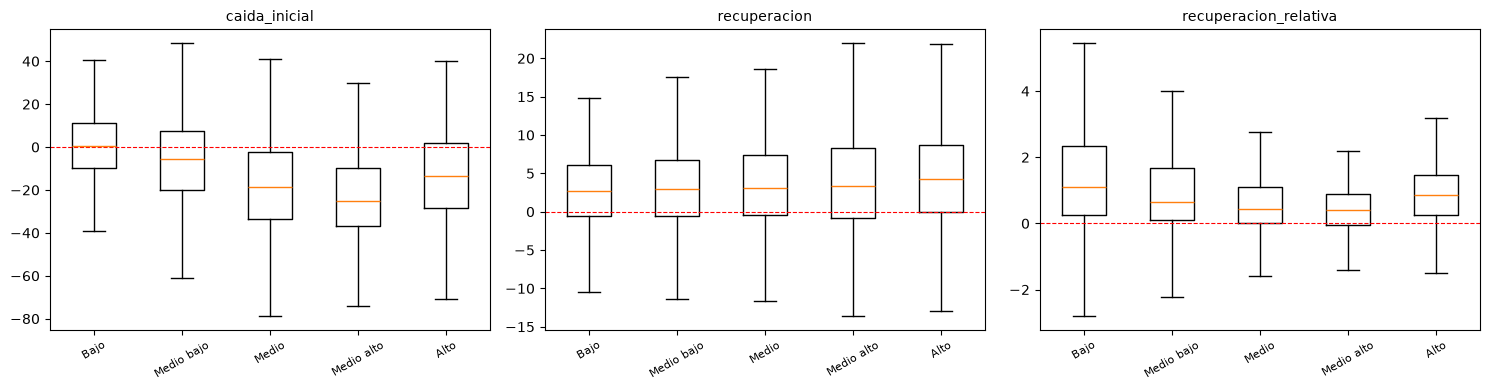

In [9]:
try:
    import matplotlib.pyplot as plt
    presentes = [g for g in orden_gse if g in m.cod_grupo_cat.unique()]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, med in zip(axes, MEDIDAS):
        datos_box = [m.loc[m.cod_grupo_cat == g, med].dropna() for g in presentes]
        # El nombre del parámetro de etiquetas cambió entre versiones de
        # matplotlib ('labels' -> 'tick_labels'), por lo que se asignan aparte.
        ax.boxplot(datos_box, showfliers=False)
        ax.set_xticks(range(1, len(presentes) + 1))
        ax.set_xticklabels(presentes, rotation=30, fontsize=8)
        ax.axhline(0, color="red", ls="--", lw=0.8)
        ax.set_title(med, fontsize=10)
    plt.tight_layout(); plt.show()
except ImportError:
    print("matplotlib no disponible.")

### 3.2 Dependencia administrativa y ruralidad

In [10]:
D.resumen_por_grupo(m, "cod_depe1_cat")

,n,caida_inicial_media,caida_inicial_mediana,recuperacion_media,recuperacion_mediana,recuperacion_relativa_media,recuperacion_relativa_mediana,grupo_pequeno
cod_depe1_cat,,,,,,,,
Particular subvencionado,1520,-15.88,-16.00,3.35,3.0,0.81,0.47,False
Particular pagado,418,-11.39,-12.42,4.17,4.3,1.31,0.83,False
Municipal DAEM,391,-1.52,-0.25,3.36,3.0,1.69,1.15,False
Servicio Local de Educación,305,0.55,1.75,2.87,2.9,1.97,0.97,False
Municipal Corporación,117,-1.19,2.00,3.32,2.6,2.10,0.62,False
Corporación de administración delegada,70,-14.03,-9.38,4.89,4.4,1.89,0.62,False


In [11]:
D.resumen_por_grupo(m, "cod_rural_rbd_cat")

,n,caida_inicial_media,caida_inicial_mediana,recuperacion_media,recuperacion_mediana,recuperacion_relativa_media,recuperacion_relativa_mediana,grupo_pequeno
cod_rural_rbd_cat,,,,,,,,
Urbano,2671,-11.33,-10.25,3.44,3.1,1.08,0.59,False
Rural,150,-1.36,-2.58,3.88,4.1,2.12,1.22,False


**Advertencia sobre la lectura rural.** Los establecimientos rurales son pequeños y sus puntajes se suprimen con más frecuencia, de modo que están subrepresentados en la muestra (ver sección 2). Un promedio rural favorable puede reflejar que solo sobrevivieron al filtro los colegios rurales más grandes, no que el mundo rural se recuperara mejor.

### 3.3 Región

In [12]:
r_reg = D.resumen_por_grupo(m, "region_dir")
r_reg.head(20)

,n,caida_inicial_media,caida_inicial_mediana,recuperacion_media,recuperacion_mediana,recuperacion_relativa_media,recuperacion_relativa_mediana,grupo_pequeno
region_dir,,,,,,,,
13,1002,-10.22,-9.00,3.64,3.60,1.23,0.68,False
5,368,-15.28,-13.25,2.94,2.60,0.75,0.38,False
8,224,-10.28,-7.75,3.59,3.55,1.14,0.59,False
9,174,-7.20,-7.88,3.87,3.15,1.66,0.77,False
7,165,-10.55,-10.75,4.80,4.40,1.71,0.96,False
10,153,-9.32,-9.75,1.79,2.10,0.60,0.31,False
4,150,-12.17,-14.00,2.86,2.35,0.66,0.43,False
6,147,-12.94,-11.25,3.54,3.10,0.89,0.66,False
16,88,-11.01,-9.62,4.19,3.95,1.70,0.71,False


### 3.4 Variables geográficas

Para las continuas se usan quintiles, que permiten ver si la relación con la recuperación es monótona o tiene forma.

In [13]:
for var in ["densidad_5km", "dist_referencia_km", "dist_centroide_comuna_km"]:
    if var not in m.columns:
        continue
    m[f"q_{var}"] = pd.qcut(m[var], 5, labels=[f"Q{i}" for i in range(1, 6)],
                            duplicates="drop")
    print(f"=== {var}")
    display(D.resumen_por_grupo(m, f"q_{var}").sort_index())

=== densidad_5km


,n,caida_inicial_media,caida_inicial_mediana,recuperacion_media,recuperacion_mediana,recuperacion_relativa_media,recuperacion_relativa_mediana,grupo_pequeno
q_densidad_5km,,,,,,,,
Q1,580,-5.00,-3.38,2.96,2.80,1.38,0.79,False
Q2,558,-13.97,-13.62,4.14,3.60,1.21,0.53,False
Q3,586,-11.94,-11.50,3.42,2.95,0.86,0.50,False
Q4,534,-12.40,-12.25,3.35,3.00,1.16,0.57,False
Q5,563,-10.90,-9.00,3.44,3.40,1.08,0.61,False


=== dist_referencia_km


,n,caida_inicial_media,caida_inicial_mediana,recuperacion_media,recuperacion_mediana,recuperacion_relativa_media,recuperacion_relativa_mediana,grupo_pequeno
q_dist_referencia_km,,,,,,,,
Q1,565,-9.98,-8.50,3.72,3.70,1.22,0.75,False
Q2,564,-10.95,-9.75,3.54,3.25,1.32,0.58,False
Q3,564,-13.66,-12.00,3.52,3.20,0.91,0.56,False
Q4,564,-10.65,-9.50,3.82,3.40,1.33,0.60,False
Q5,564,-8.74,-7.71,2.69,2.50,0.86,0.51,False


=== dist_centroide_comuna_km


,n,caida_inicial_media,caida_inicial_mediana,recuperacion_media,recuperacion_mediana,recuperacion_relativa_media,recuperacion_relativa_mediana,grupo_pequeno
q_dist_centroide_comuna_km,,,,,,,,
Q1,565,-9.60,-7.25,3.00,2.70,1.13,0.53,False
Q2,564,-12.34,-11.88,3.51,3.25,0.89,0.52,False
Q3,564,-11.82,-10.25,4.08,3.55,1.27,0.72,False
Q4,564,-10.27,-11.00,3.59,3.60,1.17,0.68,False
Q5,564,-9.94,-9.25,3.11,3.05,1.17,0.53,False


## 4. Rupturas sostenidas

Los 213 establecimientos con ruptura entran al análisis **con un indicador**, no se excluyen: son el fenómeno más marcado que muestran los datos y descartarlos equivaldría a borrar el hallazgo. El indicador permite controlarlos en el modelo y correr un análisis de sensibilidad sin ellos.

In [14]:
print(m.tipo_trayectoria.value_counts().to_string())
print()
D.resumen_por_grupo(m, "tipo_trayectoria")

tipo_trayectoria
normal               2490
ruptura sostenida     213
atípico 2022          118



,n,caida_inicial_media,caida_inicial_mediana,recuperacion_media,recuperacion_mediana,recuperacion_relativa_media,recuperacion_relativa_mediana,grupo_pequeno
tipo_trayectoria,,,,,,,,
normal,2490,-6.88,-7.25,3.30,3.00,1.26,0.72,False
ruptura sostenida,213,-43.50,-49.50,2.79,2.80,0.21,0.21,False
atípico 2022,118,-34.48,-45.38,8.08,9.45,0.76,0.74,False


In [15]:
# ¿Dónde están? Composición de las rupturas por GSE y dependencia.
rup = m[m.ruptura_sostenida.fillna(False)]
for var in ["cod_grupo_cat", "cod_depe1_cat", "region_dir"]:
    pct = (100 * rup[var].value_counts() / m[var].value_counts()).dropna().round(1)
    print(f"=== % con ruptura por {var}")
    print(pct.sort_values(ascending=False).head(6).to_string())
    print()

=== % con ruptura por cod_grupo_cat
cod_grupo_cat
Medio alto    14.4
Medio         13.7
Medio bajo     5.4
Alto           3.7
Bajo           1.9

=== % con ruptura por cod_depe1_cat
cod_depe1_cat
Particular subvencionado                  10.5
Corporación de administración delegada     7.1
Servicio Local de Educación                4.6
Municipal DAEM                             4.6
Particular pagado                          3.1
Municipal Corporación                      2.6

=== % con ruptura por region_dir
region_dir
8     11.6
6     10.2
2      9.8
5      9.2
4      8.0
10     7.8



## 5. Correlaciones entre las medidas y las covariables continuas

Una primera lectura de qué variables se asocian con cada medida, antes de modelar. Son correlaciones bivariadas: no controlan por nada y no deben leerse como efectos.

In [16]:
continuas = ["puntaje_pre", "matricula_pre", "var_matricula_pct",
             "densidad_5km", "densidad_10km", "dist_vecino_km",
             "dist_centroide_comuna_km", "dist_referencia_km"]
continuas = [c for c in continuas if c in m.columns]

corr = m[list(MEDIDAS) + continuas].corr(numeric_only=True).loc[continuas, list(MEDIDAS)]
corr.round(3).sort_values("recuperacion", ascending=False)

,caida_inicial,recuperacion,recuperacion_relativa
puntaje_pre,-0.548,0.087,-0.175
densidad_10km,-0.016,0.022,0.004
densidad_5km,-0.045,0.021,-0.017
matricula_pre,-0.140,0.014,-0.032
var_matricula_pct,0.044,-0.005,-0.016
dist_vecino_km,0.036,-0.018,0.008
dist_referencia_km,0.043,-0.037,-0.023
dist_centroide_comuna_km,-0.011,-0.039,-0.022


**Una relación que conviene mirar aparte.** La correlación entre `puntaje_pre` y `caida_inicial` es negativa y fuerte. Que r(PRE, caída) y r(PRE, 2022) tengan signos opuestos **no demuestra** regresión a la media: el patrón también es compatible con un efecto real del nivel previo. La prueba correcta, en la sección 5.1, compara la correlación observada con la que produciría el puro error de medición del PRE.

In [17]:
# Evidencia de la regresión a la media: correlación entre el nivel previo
# y el cambio, frente a la correlación entre el nivel previo y el nivel posterior.
print("corr(puntaje_pre, caida_inicial)      =",
      round(float(m.puntaje_pre.corr(m.caida_inicial)), 3))
print("corr(puntaje_pre, puntaje_impacto)    =",
      round(float(m.puntaje_pre.corr(m.puntaje_impacto)), 3))
print("corr(puntaje_pre, recuperacion)       =",
      round(float(m.puntaje_pre.corr(m.recuperacion)), 3))

corr(puntaje_pre, caida_inicial)      = -0.548
corr(puntaje_pre, puntaje_impacto)    = 0.849
corr(puntaje_pre, recuperacion)       = 0.087


## 5.1 Verificaciones de la revisión del 1-oct-2026

### Regresión a la media o efecto del nivel previo (comentario 37)

Se estima la confiabilidad del PRE por mitades (2015–16 frente a 2017–18, corrección de Spearman-Brown). Bajo puro error clásico, cov(PRE, caída) = −var(error); si la correlación observada es mucho más negativa que la esperada, la relación es sustantiva.

In [18]:
R = sp.robustez
rel = R.confiabilidad_pre(ancho, m)
rel

15:14:49 | INFO    | simce_panel.robustez | Confiabilidad PRE: {'r_mitades': 0.951, 'confiabilidad': 0.975, 'r_observada': -0.548, 'r_esperada_solo_error': -0.048}


{'r_mitades': 0.951,
 'confiabilidad': 0.975,
 'r_observada': -0.548,
 'r_esperada_solo_error': -0.048}

**Lectura.** Con una confiabilidad cercana a 0,97, el error de medición explica una correlación de alrededor de −0,05, mientras la observada ronda −0,55. La relación no es regresión a la media: los establecimientos con mayor nivel previo cayeron más. Coincide con el CIAE (2023), que encuentra mayores pérdidas en las escuelas más efectivas antes de la pandemia. La decisión de controlar por PRE se mantiene; lo que cambia es su justificación.

### Correlación caída–recuperación por construcción (comentario 11)

El puntaje de 2022 es el punto final de la caída y el primero de la pendiente. Su error de muestreo produce una correlación negativa por construcción.

In [19]:
n22 = pd.to_numeric(ancho.set_index("rbd")[f"nalu_{MATERIA}2m_rbd_2022"], errors="coerce")
R.correlacion_por_construccion(m, n22)

{'r_observada': -0.273,
 'r_esperada_por_ruido_2022': -0.089,
 'var_ruido_2022': 46.3}

Una parte de la correlación observada se explica solo por el ruido de 2022. El modelo de medición del notebook 06 estima caída y pendiente de forma conjunta y separa ambas componentes.

### Traspasos efectivos a SLEP (comentario 14)

Los cambios de dependencia del panel incluyen oscilaciones de un año. Se cuentan los traspasos efectivos comparando la dependencia más frecuente de cada período.

In [20]:
largo = sp.io_datos.leer_csv(cfg.ruta_salida(sp.config.NOMBRES_SALIDA["rbd"]))
largo, _ = sp.estandarizacion.estandarizar_canonico(largo, variables=["cod_depe1"])
R.traspasos_slep(largo, m["rbd"], col_depe="cod_depe1_cat")

{'cambian_dependencia': 153,
 'traspaso_municipal_a_slep': 113,
 'municipales_sin_cambio': 699}

### Magnitud del cambio de GSE en las rupturas (comentario 36)

13,6 % frente a 8,6 % es una proporción **58 % mayor** (razón 1,58), no una diferencia menor. La decisión de incluir el cambio de GSE como control se mantiene.

## 6. Guardado

El dataset analítico queda listo para el análisis espacial (OE3) y el modelamiento (OE4).

In [21]:
ruta = cfg.ruta_salida(f"dataset_analitico_{MATERIA}.csv")
sp.io_datos.escribir_csv(datos, ruta)
print("Guardado:", ruta)
print("Filas:", len(datos), "| en muestra analítica:", int(datos.en_muestra.sum()))
print("Columnas:", datos.shape[1])

Guardado: Dataset\Unificados\dataset_analitico_mate.csv
Filas: 3144 | en muestra analítica: 2821
Columnas: 40


---
### Qué sigue

| Notebook | Objetivo | Contenido |
|---|---|---|
| 05 | OE3 · H1, H2 | Moran sobre los residuos del modelo de línea base, LISA con Benjamini-Hochberg, sensibilidad a la matriz de pesos y mínimo detectable |
| 06 | OE4 · H3b | Modelo bayesiano jerárquico de serie interrumpida: caída y recuperación por establecimiento, con su intervalo |
| 07 | OE2 | Covariables externas: participación, IVE e IVM de JUNAEB, pobreza y densidad comunal, distancia a la capital regional |
| 08 | OE3 · H1 | Modelo BYM2 por comuna |
| 09 | OE4 · H3, H5 | Gradiente socioeconómico dentro del modelo y traspaso a SLEP emparejado; SHAP como análisis complementario |
| 10 | OE4 · C3 | Validación predictiva con 2025 reservado frente al lineal jerárquico |
| 11 | OE4 · H3 | Robustez de H3 con tres especificaciones de covariables |
| 12 | OE4 · H4 | Contribución de la geografía y la dependencia en rurales y urbanos, validada por simulación |